# 09 — Démo : retrieval dense (G1 Naive RAG) avec la release figée

Montre comment **tous les groupes** chargent la release, interrogent l'index, et comment le garde-fou anti-fuite fonctionne.

In [1]:
import os
# --- paramètre : "config.yaml" = vraies données COCO ; "config_test.yaml" = mini-COCO synthétique (test sans réseau)
CONFIG = os.environ.get("RAG_CONFIG", "config.yaml")
os.environ["RAG_CONFIG"] = CONFIG
print("config utilisée :", CONFIG)

config utilisée : config.yaml


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, textwrap
from PIL import Image
from common import load_config, paths, clean_caption
from rag_data import Release
cfg = load_config(); P = paths(cfg)
R = Release(P["art"], cfg["primary_encoder"])
print("encodeur :", R.encoder, "| KB :", len(R.ids("kb")), "images | test :", len(R.ids("test")), "images")

encodeur : clip-b32 | KB : 10000 images | test : 100 images


## 1. Requête : image de test + références (uniquement pour l'évaluation)

In [3]:
ids, Q = R.ids("test"), R.image_embeddings("test")
refs, M = R.eval_refs("test"), R.metadata()
n = 0
print("image_id :", ids[n]); print("références :", *refs[int(ids[n])], sep="\n - "); print("classes (annotations) :", M[int(ids[n])]["category_counts"])

image_id : 2261
références :
 - A man on a blue raft attempting to catch a ride on a large wave.
 - The boy is looking back at a wave in the ocean. 
 - A young man is body surfing and paddling in the water.
 - A man in a black shirt plays on an ocean wave.
 - A boy riding a boogie board in the ocean waves.
classes (annotations) : {'person': 1, 'surfboard': 1}


## 2. Top-5 images de la base de connaissances (cosinus, FAISS)

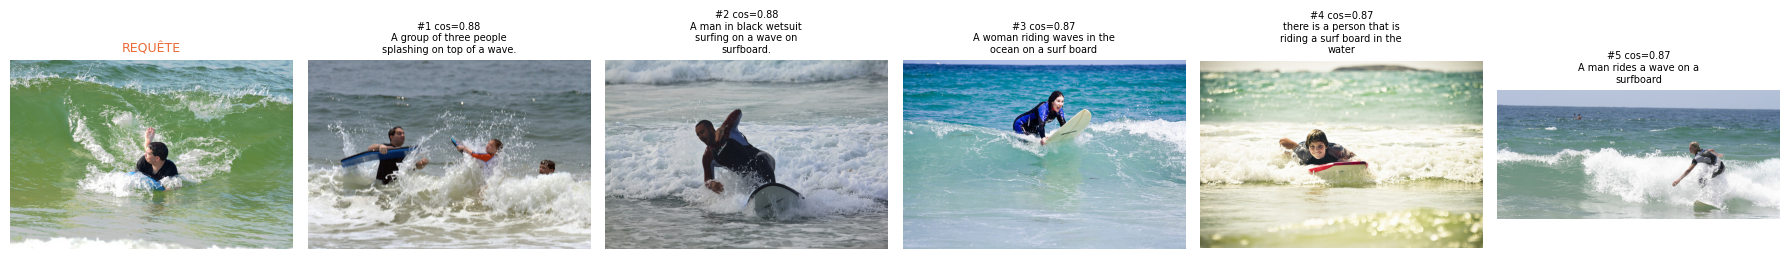

In [4]:
S, I = R.search_images(Q, k=5, query_ids=ids)       # garde-fou : erreur si une image se retrouve elle-même
fig, axs = plt.subplots(1, 6, figsize=(18, 4))
axs[0].imshow(Image.open(R.image_path("test", ids[n]))); axs[0].set_title("REQUÊTE", fontsize=9, color="#eb6834")
for k in range(5):
    j = int(I[n, k]); axs[k + 1].imshow(Image.open(R.image_path("kb", j)))
    axs[k + 1].set_title(f"#{k + 1} cos={S[n, k]:.2f}\n" + textwrap.fill(R.kb_captions_of(j)[0], 28), fontsize=7)
for a in axs: a.axis("off")
plt.tight_layout(); plt.show()

## 3. Recherche image → texte (espace CLIP/SigLIP, si l'encodeur a une tour texte)

In [5]:
try:
    St, cids, iids = R.search_texts(Q[n:n + 1], k=5)
    capmap = {c["caption_id"]: c["caption_raw"] for c in R.kb_captions()}
    for s, c, i in zip(St[0], cids[0], iids[0]): print(f"{s:.3f}  (img {i})  {capmap[int(c)]}")
except FileNotFoundError:
    print("pas d'embeddings texte pour cet encodeur (ex. DINOv2)")

0.330  (img 512211)  The young man smiles while bodyboarding in the ocean. 
0.327  (img 467580)  A person is wiping out riding a surfboard on the waves.
0.326  (img 538214)  A young boy is surfing on a wave in a body of water. 
0.326  (img 360143)  A person riding a wave on a surfboard near a swimmer.
0.324  (img 367905)  A man in black shirt falling off of a surfboard in ocean.


## 4. Garde-fou anti-fuite : une image requête ne peut jamais être retrouvée elle-même

In [6]:
try:
    R.search_images(R.image_embeddings("kb")[:3], k=1, query_ids=R.ids("kb")[:3])   # on interroge la KB avec ses propres images
except AssertionError as e:
    print("garde-fou OK ->", e)

garde-fou OK -> FUITE : une image requête a été retrouvée elle-même


## 5. Baseline de référence : caption de l'image la plus proche (NN-caption) vs aléatoire — CIDEr sur test

In [7]:
from pycocoevalcap.cider.cider import Cider
rng = np.random.RandomState(0); kb_ids = R.ids("kb")
def cider(res):
    s, _ = Cider().compute_score({i: [clean_caption(x) for x in refs[i]] for i in refs}, {i: [clean_caption(res[i])] for i in refs}); return s
nn = {int(i): R.kb_captions_of(I[k, 0])[0] for k, i in enumerate(ids)}
rd = {int(i): R.kb_captions_of(rng.choice(kb_ids))[0] for i in ids}
print(f"CIDEr NN-caption = {cider(nn):.3f} | aléatoire = {cider(rd):.3f}")

CIDEr NN-caption = 0.612 | aléatoire = 0.047


In [8]:
St, cids, iids = R.search_texts(Q, k=1)
capmap = {c["caption_id"]: c["caption_raw"] for c in R.kb_captions()}
nn_txt = {int(i): capmap[int(cids[k, 0])] for k, i in enumerate(ids)}
print(f"CIDEr img2txt = {cider(nn_txt):.3f} | img2img = {cider(nn):.3f} | aléatoire = {cider(rd):.3f}")

CIDEr img2txt = 0.650 | img2img = 0.612 | aléatoire = 0.047
